# Model Selection

**Benchamarked Models (regression problem)**

- Explainable Boosting (GAM ensemble boosting)
https://interpret.ml/docs/python/api/ExplainableBoostingRegressor.html

- Random Forest (ensemble bagging)
https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html

- Extreme Gradient Boosting (ensemble boosting)
https://xgboost.readthedocs.io/en/stable/parameter.html 

- Super Vector (kernel)
https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html#sklearn.svm.SVR

- Elastic Net (regularized linear)
https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html#sklearn.linear_model.ElasticNet

- Deep Learning (neural networks)
https://docs.fast.ai/


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path

In [2]:
import scipy.stats as ss
import scikit_posthocs as sp

In [3]:
sns.set_theme(style="darkgrid")
sns.set_palette('tab10')

## Analysis of the model selection

Hyperparameter selection was performed using the results obtained across the 40 benchmark projects. First, the 50 Latin Hypercube configurations were ranked separately within each project according to `RelMSE`, with lower error receiving a better rank. The configurations were then ordered by their average rank across projects.

To reduce the number of pairwise comparisons, only the top `k=10` configurations according to average rank were retained. A Friedman test was applied to this subset to assess whether there were statistically significant differences among the selected configurations. If the null hypothesis was rejected, a Conover post-hoc test with multiple-comparison correction was used to identify pairwise differences.

Finally, if several top configurations were statistically indistinguishable, the final choice was made using parsimony criteria such as lower computational cost, lower variability, or simpler hyperparameter values.

In [35]:
results_dir = "./model_selection/results"
hyperparameters_dir = "./model_selection/hyperparameters"
work_dir = "./model_selection"

### Statistical comparison function

In [14]:
# Statistical comparison of hyperparameter configurations
def model_comparison(data, significance=0.05, figsize=(15, 4)):
    # Rank configurations: lower error is better
    rank = data.rank(axis=1, pct=True, ascending=True)
    avg_rank = rank.mean().sort_values()

    best_lhs = avg_rank.index[0]

    # Friedman test
    friedman_test = ss.friedmanchisquare(*data.values.T)
    print(f"Friedman's test p-value: {friedman_test.pvalue}")

    result = {
        "best_lhs": best_lhs,
        "avg_rank": avg_rank,
        "friedman_pvalue": friedman_test.pvalue,
        "conover_test": None,
        "best_not_significantly_different": [best_lhs],
    }

    if friedman_test.pvalue < significance:
        print("Reject null hypothesis that all configurations are equally good")
        print("Conover's test for all pairs of configurations...\n")

        conover_test = sp.posthoc_conover_friedman(
            data,
            p_adjust="bonferroni"
        )

        # Configurations not significantly different from the best one
        best_group = (
            conover_test.loc[best_lhs]
            [conover_test.loc[best_lhs] >= significance]
            .index
            .tolist()
        )

        # Keep them ordered by average rank
        best_group = avg_rank.loc[best_group].sort_values().index.tolist()

        result["conover_test"] = conover_test
        result["best_not_significantly_different"] = best_group

        plt.figure(figsize=figsize)
        plt.title("Critical difference diagram of normalized score ranks")
        sp.critical_difference_diagram(avg_rank, conover_test)
        plt.show()

        print(f"Best configuration by average rank: {best_lhs}")
        print(
            "Configurations not significantly different from the best: "
            f"{best_group}"
        )

    else:
        print("Do not reject null hypothesis that all configurations are equally good")
        print(f"Best configuration by average rank: {best_lhs}")

    return result


### Load results function

In [15]:
def load_results(model: str,results_dir: Path) -> pd.DataFrame:

    # Load results for the specified model
    files = sorted(results_dir.glob(f"lhs_model_selection_{model}_project_*.csv"))
    if len(files) != 40:
        print(f"Warning: Expected 40 result files for {model}, but found {len(files)}")

    # Read and concatenate results
    dfs = []
    for file in files:
        df = pd.read_csv(file)
        required_cols = ["model", "project", "lhs", "RelMSE"]
        df = df[required_cols].copy()
        dfs.append(df)

    results = pd.concat(dfs, ignore_index=True)
    results["model"] = results["model"].astype(str)
    results["project"] = results["project"].astype(str)
    results["lhs"] = results["lhs"].astype(int)
    results["RelMSE"] = pd.to_numeric(results["RelMSE"], errors="raise")

    # Check integrity of the results
    if (results.groupby('project').count()['lhs']!=50).any():
        print("Warning: Not all projects have 50 LHS samples.")
    if (results.groupby('lhs').count()['project']!=40).any():
        print("Warning: Not all LHS samples have 40 projects.")
    
    return results

### EBM

In [16]:
# Load the results for the specified model
model='ebm'
results=load_results(model,Path(results_dir))

# Order by their average rank across projects

# Build a matrix with RelMSE values for the specified model
data=(results.loc[results['model']==model,['lhs','project','RelMSE']].
    pivot(index='project',columns='lhs',values='RelMSE')) # 40x50=2000 samples

# Rank the hyperparameter configurations for each project (lower RelMSE gets better rank) 
ranks = data.rank(axis=1, ascending=True, method="average")

# Summarize the performance of each hyperparameter configuration
summary = pd.DataFrame({
    "mean_rank": ranks.mean(),
    "median_rank": ranks.median(),
    "std_rank": ranks.std(),
    "mean_RelMSE": data.mean(),
    "median_RelMSE": data.median(),
    "wins": data.idxmin(axis=1).value_counts(),
})
summary["wins"] = summary["wins"].fillna(0).astype(int)

summary = (
    summary
    .sort_values(["mean_rank", "mean_RelMSE"])
    .reset_index()
    .rename(columns={"index": "lhs"})
)

summary.head(10)

,lhs,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,wins
0,24,7.625,6.5,5.700596,0.014880,0.001782,3
1,13,10.225,10.0,6.199617,0.015541,0.001818,1
2,14,11.375,6.0,11.639208,0.014524,0.001748,5
3,15,11.425,9.0,7.034302,0.017154,0.001799,0
4,39,11.700,5.5,12.529350,0.020258,0.001785,16
5,31,12.675,11.0,8.468304,0.018242,0.001851,0
6,43,13.425,13.0,5.068189,0.015697,0.001821,0
7,2,13.800,11.0,7.916876,0.018203,0.001808,0
8,0,13.900,13.5,7.181886,0.015969,0.001891,0
9,44,14.775,15.0,6.006353,0.016652,0.001822,0


Friedman's test p-value: 7.82891900373617e-10
Reject null hypothesis that all configurations are equally good
Conover's test for all pairs of configurations...



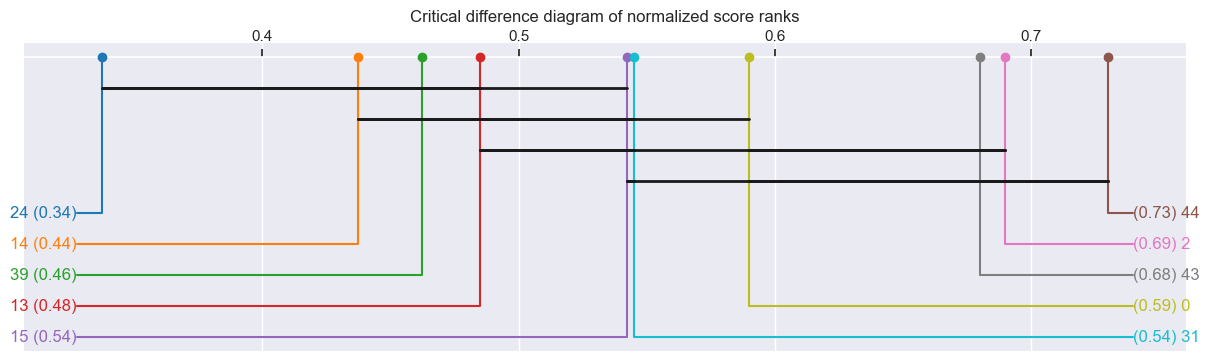

Best configuration by average rank: 24
Configurations not significantly different from the best: [24, 14, 39, 13, 15]


,lhs,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,wins
0,24,7.625,6.5,5.700596,0.014880,0.001782,3
1,13,10.225,10.0,6.199617,0.015541,0.001818,1
2,14,11.375,6.0,11.639208,0.014524,0.001748,5
3,15,11.425,9.0,7.034302,0.017154,0.001799,0
4,39,11.700,5.5,12.529350,0.020258,0.001785,16


In [17]:
# Statistical comparison of top 10 hyperparameter configurations
topk=summary.head(10).lhs.tolist()
data=(results.loc[(results['model']==model) & (results['lhs'].isin(topk)),['lhs','project','RelMSE']].
    pivot(index='project',columns='lhs',values='RelMSE')) 
comparison = model_comparison(data)
best_lhs = comparison["best_lhs"] # best configuration by average rank
best_group = comparison["best_not_significantly_different"] # configurations not significantly different from the best one

summary[summary['lhs'].isin(best_group)].sort_values('mean_rank')

The primary criterion was the average rank across projects. When several configurations showed similar average ranks, stability across projects was used as a secondary criterion (lower variability in std rank)

Dataframe for the best models' hyperparametrizations

In [18]:
lhs_choice = 24
models = pd.DataFrame({
    f'ebm-{lhs_choice}': data[lhs_choice]
})


### Random Forest

In [19]:
# Load the results for the specified model
model='rf'
results=load_results(model,Path(results_dir))

# Order by their average rank across projects

# Build a matrix with RelMSE values for the specified model
data=(results.loc[results['model']==model,['lhs','project','RelMSE']].
    pivot(index='project',columns='lhs',values='RelMSE')) # 40x50=2000 samples

# Rank the hyperparameter configurations for each project (lower RelMSE gets better rank) 
ranks = data.rank(axis=1, ascending=True, method="average")

# Summarize the performance of each hyperparameter configuration
summary = pd.DataFrame({
    "mean_rank": ranks.mean(),
    "median_rank": ranks.median(),
    "std_rank": ranks.std(),
    "mean_RelMSE": data.mean(),
    "median_RelMSE": data.median(),
    "wins": data.idxmin(axis=1).value_counts(),
})
summary["wins"] = summary["wins"].fillna(0).astype(int)

summary = (
    summary
    .sort_values(["mean_rank", "mean_RelMSE"])
    .reset_index()
    .rename(columns={"index": "lhs"})
)

summary.head(10)

,lhs,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,wins
0,14,2.425,2.0,1.430214,0.176734,0.177815,14
1,12,3.450,3.0,1.810935,0.176972,0.176616,5
2,8,3.675,4.0,2.280210,0.177104,0.178756,8
3,17,5.075,5.0,2.484697,0.177527,0.177810,5
4,25,5.875,5.5,2.503203,0.177942,0.178549,0
5,5,6.100,7.0,3.499451,0.178181,0.179278,7
6,9,6.725,6.0,3.088336,0.178322,0.178556,0
7,26,8.125,8.0,1.963611,0.178934,0.178934,0
8,33,8.150,8.0,3.017470,0.178851,0.179698,0
9,36,9.350,9.5,3.285945,0.179463,0.179849,1


Friedman's test p-value: 4.2332527683415594e-29
Reject null hypothesis that all configurations are equally good
Conover's test for all pairs of configurations...



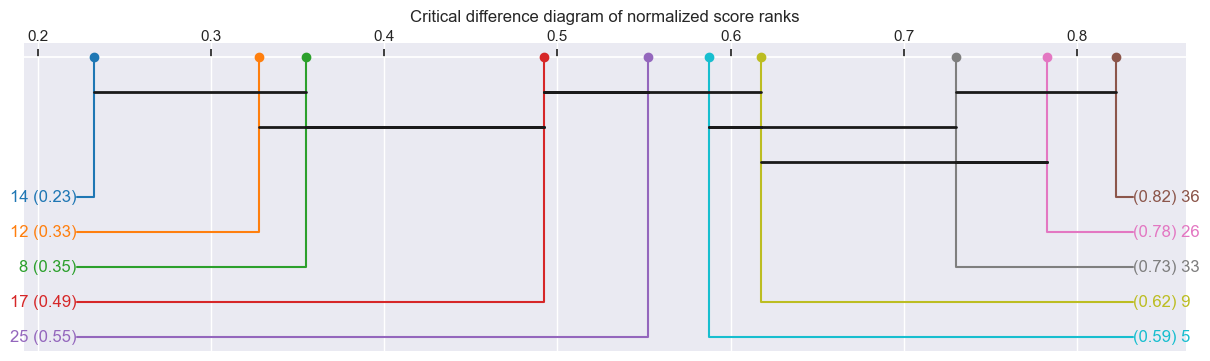

Best configuration by average rank: 14
Configurations not significantly different from the best: [14, 12, 8]


,lhs,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,wins
0,14,2.425,2.0,1.430214,0.176734,0.177815,14
1,12,3.450,3.0,1.810935,0.176972,0.176616,5
2,8,3.675,4.0,2.280210,0.177104,0.178756,8


In [20]:
# Statistical comparison of top 10 hyperparameter configurations
topk=summary.head(10).lhs.tolist()
data=(results.loc[(results['model']==model) & (results['lhs'].isin(topk)),['lhs','project','RelMSE']].
    pivot(index='project',columns='lhs',values='RelMSE')) 
comparison = model_comparison(data)
best_lhs = comparison["best_lhs"] # best configuration by average rank
best_group = comparison["best_not_significantly_different"] # configurations not significantly different from the best one

summary[summary['lhs'].isin(best_group)].sort_values('mean_rank')

In [21]:
lhs_choice = 14
models[f'rf-{lhs_choice}'] = data[lhs_choice]

### XGBoost

In [22]:
# Load the results for the specified model
model='xgb'
results=load_results(model,Path(results_dir))

# Order by their average rank across projects

# Build a matrix with RelMSE values for the specified model
data=(results.loc[results['model']==model,['lhs','project','RelMSE']].
    pivot(index='project',columns='lhs',values='RelMSE')) # 40x50=2000 samples

# Rank the hyperparameter configurations for each project (lower RelMSE gets better rank) 
ranks = data.rank(axis=1, ascending=True, method="average")

# Summarize the performance of each hyperparameter configuration
summary = pd.DataFrame({
    "mean_rank": ranks.mean(),
    "median_rank": ranks.median(),
    "std_rank": ranks.std(),
    "mean_RelMSE": data.mean(),
    "median_RelMSE": data.median(),
    "wins": data.idxmin(axis=1).value_counts(),
})
summary["wins"] = summary["wins"].fillna(0).astype(int)

summary = (
    summary
    .sort_values(["mean_rank", "mean_RelMSE"])
    .reset_index()
    .rename(columns={"index": "lhs"})
)

summary.head(10)

,lhs,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,wins
0,39,3.250,2.0,2.599310,0.028742,0.016187,4
1,2,4.950,6.0,2.275285,0.029181,0.020360,4
2,26,6.575,7.0,2.308152,0.030652,0.021005,1
3,12,7.050,6.0,3.178050,0.031198,0.019063,0
4,8,7.350,4.0,7.647859,0.033106,0.016823,0
5,14,7.750,1.0,12.048513,0.033406,0.010376,25
6,13,8.475,11.0,4.169409,0.031849,0.024996,6
7,34,8.875,5.0,7.653347,0.034169,0.017604,0
8,29,9.750,11.0,4.105968,0.033059,0.024792,0
9,45,10.675,10.0,5.225124,0.035328,0.023797,0


Friedman's test p-value: 2.2920877174645526e-19
Reject null hypothesis that all configurations are equally good
Conover's test for all pairs of configurations...



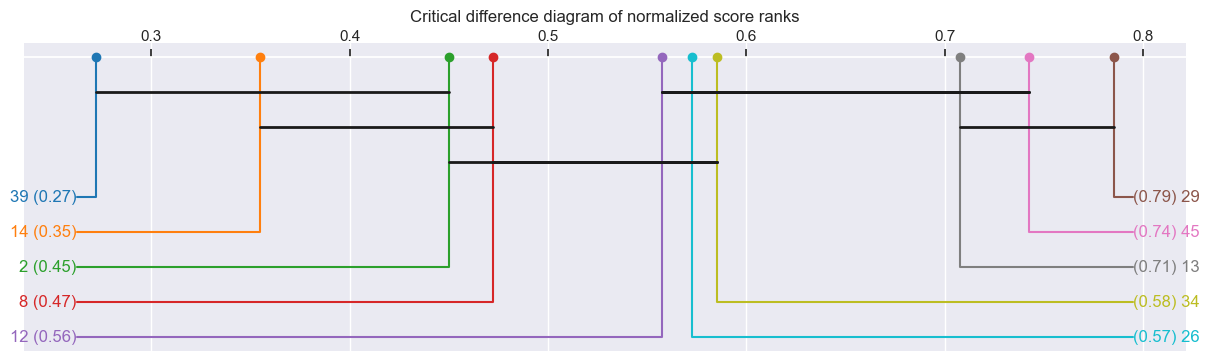

Best configuration by average rank: 39
Configurations not significantly different from the best: [39, 14, 2]


,lhs,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,wins
0,39,3.25,2.0,2.599310,0.028742,0.016187,4
1,2,4.95,6.0,2.275285,0.029181,0.020360,4
5,14,7.75,1.0,12.048513,0.033406,0.010376,25


In [23]:
# Statistical comparison of top 10 hyperparameter configurations
topk=summary.head(10).lhs.tolist()
data=(results.loc[(results['model']==model) & (results['lhs'].isin(topk)),['lhs','project','RelMSE']].
    pivot(index='project',columns='lhs',values='RelMSE')) 
comparison = model_comparison(data)
best_lhs = comparison["best_lhs"] # best configuration by average rank
best_group = comparison["best_not_significantly_different"] # configurations not significantly different from the best one

summary[summary['lhs'].isin(best_group)].sort_values('mean_rank')

In [24]:
lhs_choice = 39
models[f'xg-{lhs_choice}'] = data[lhs_choice]

### Super Vector

In [25]:
# Load the results for the specified model
model='sv'
results=load_results(model,Path(results_dir))

# Order by their average rank across projects

# Build a matrix with RelMSE values for the specified model
data=(results.loc[results['model']==model,['lhs','project','RelMSE']].
    pivot(index='project',columns='lhs',values='RelMSE')) # 40x50=2000 samples

# Rank the hyperparameter configurations for each project (lower RelMSE gets better rank) 
ranks = data.rank(axis=1, ascending=True, method="average")

# Summarize the performance of each hyperparameter configuration
summary = pd.DataFrame({
    "mean_rank": ranks.mean(),
    "median_rank": ranks.median(),
    "std_rank": ranks.std(),
    "mean_RelMSE": data.mean(),
    "median_RelMSE": data.median(),
    "wins": data.idxmin(axis=1).value_counts(),
})
summary["wins"] = summary["wins"].fillna(0).astype(int)

summary = (
    summary
    .sort_values(["mean_rank", "mean_RelMSE"])
    .reset_index()
    .rename(columns={"index": "lhs"})
)

summary.head(10)

,lhs,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,wins
0,0,2.100,2.0,1.481510,0.034062,0.024987,19
1,41,2.875,2.0,1.180775,0.034356,0.025047,1
2,31,3.750,3.0,1.192928,0.035054,0.025207,1
3,27,4.350,3.0,4.498148,0.037171,0.024422,18
4,44,5.550,5.0,1.616422,0.035858,0.025819,0
5,45,7.050,7.0,1.907475,0.036679,0.026180,0
6,30,7.450,6.0,5.363457,0.039211,0.025095,0
7,16,8.475,8.0,1.260596,0.038353,0.026226,0
8,13,9.400,9.0,2.193230,0.038464,0.026935,0
9,22,10.575,10.0,2.061708,0.038930,0.027222,0


Friedman's test p-value: 3.6937570383973695e-49
Reject null hypothesis that all configurations are equally good
Conover's test for all pairs of configurations...



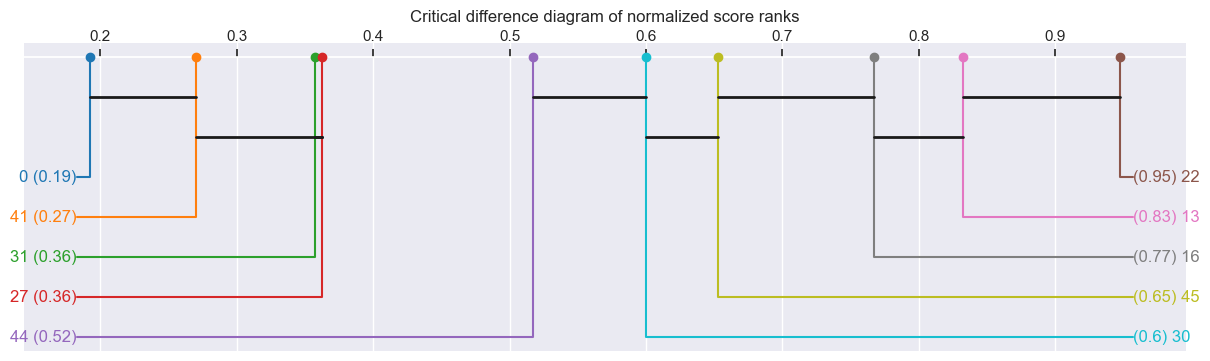

Best configuration by average rank: 0
Configurations not significantly different from the best: [0, 41]


,lhs,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,wins
0,0,2.100,2.0,1.481510,0.034062,0.024987,19
1,41,2.875,2.0,1.180775,0.034356,0.025047,1


In [26]:
# Statistical comparison of top 10 hyperparameter configurations
topk=summary.head(10).lhs.tolist()
data=(results.loc[(results['model']==model) & (results['lhs'].isin(topk)),['lhs','project','RelMSE']].
    pivot(index='project',columns='lhs',values='RelMSE')) 
comparison = model_comparison(data)
best_lhs = comparison["best_lhs"] # best configuration by average rank
best_group = comparison["best_not_significantly_different"] # configurations not significantly different from the best one

summary[summary['lhs'].isin(best_group)].sort_values('mean_rank')

In [27]:
lhs_choice = 0
models[f'sv-{lhs_choice}'] = data[lhs_choice]

### Elastic Net

In [28]:
# Load the results for the specified model
model='en'
results=load_results(model,Path(results_dir))

# Order by their average rank across projects

# Build a matrix with RelMSE values for the specified model
data=(results.loc[results['model']==model,['lhs','project','RelMSE']].
    pivot(index='project',columns='lhs',values='RelMSE')) # 40x50=2000 samples

# Rank the hyperparameter configurations for each project (lower RelMSE gets better rank) 
ranks = data.rank(axis=1, ascending=True, method="average")

# Summarize the performance of each hyperparameter configuration
summary = pd.DataFrame({
    "mean_rank": ranks.mean(),
    "median_rank": ranks.median(),
    "std_rank": ranks.std(),
    "mean_RelMSE": data.mean(),
    "median_RelMSE": data.median(),
    "wins": data.idxmin(axis=1).value_counts(),
})
summary["wins"] = summary["wins"].fillna(0).astype(int)

summary = (
    summary
    .sort_values(["mean_rank", "mean_RelMSE"])
    .reset_index()
    .rename(columns={"index": "lhs"})
)

summary.head(10)

,lhs,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,wins
0,36,4.450,4.0,2.541451,0.016238,0.001411,4
1,33,4.900,5.0,1.676382,0.015800,0.001433,3
2,21,5.800,6.0,2.040613,0.015558,0.001446,0
3,20,5.875,2.0,5.311755,0.018742,0.001409,10
4,4,6.300,6.0,1.856382,0.016680,0.001429,0
5,46,6.550,8.0,3.029344,0.015358,0.001461,2
6,19,7.975,4.5,6.545648,0.019660,0.001487,5
7,9,8.025,10.5,4.632591,0.015193,0.001487,5
8,32,8.075,8.0,1.474353,0.016881,0.001452,0
9,42,8.100,9.0,2.696627,0.015771,0.001467,0


Friedman's test p-value: 5.2014453090312855e-09
Reject null hypothesis that all configurations are equally good
Conover's test for all pairs of configurations...



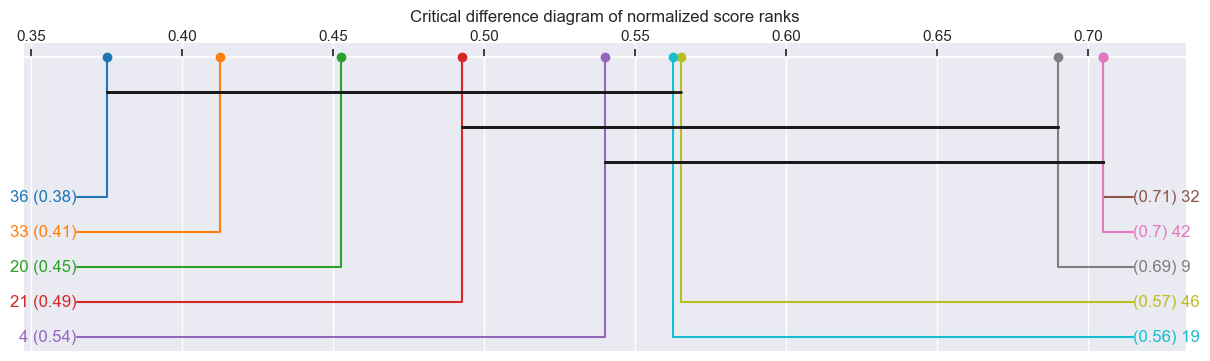

Best configuration by average rank: 36
Configurations not significantly different from the best: [36, 33, 20, 21, 4, 19, 46]


,lhs,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,wins
0,36,4.450,4.0,2.541451,0.016238,0.001411,4
1,33,4.900,5.0,1.676382,0.015800,0.001433,3
2,21,5.800,6.0,2.040613,0.015558,0.001446,0
3,20,5.875,2.0,5.311755,0.018742,0.001409,10
4,4,6.300,6.0,1.856382,0.016680,0.001429,0
5,46,6.550,8.0,3.029344,0.015358,0.001461,2
6,19,7.975,4.5,6.545648,0.019660,0.001487,5


In [29]:
# Statistical comparison of top 10 hyperparameter configurations
topk=summary.head(10).lhs.tolist()
data=(results.loc[(results['model']==model) & (results['lhs'].isin(topk)),['lhs','project','RelMSE']].
    pivot(index='project',columns='lhs',values='RelMSE')) 
comparison = model_comparison(data)
best_lhs = comparison["best_lhs"] # best configuration by average rank
best_group = comparison["best_not_significantly_different"] # configurations not significantly different from the best one

summary[summary['lhs'].isin(best_group)].sort_values('mean_rank')

In [30]:
lhs_choice = 36
models[f'en-{lhs_choice}'] = data[lhs_choice]

### FastAI tabular

In [31]:
# Load the results for the specified model
model='fastai'
results=load_results(model,Path(results_dir))

# Order by their average rank across projects

# Build a matrix with RelMSE values for the specified model
data=(results.loc[results['model']==model,['lhs','project','RelMSE']].
    pivot(index='project',columns='lhs',values='RelMSE')) # 40x50=2000 samples

# Rank the hyperparameter configurations for each project (lower RelMSE gets better rank) 
ranks = data.rank(axis=1, ascending=True, method="average")

# Summarize the performance of each hyperparameter configuration
summary = pd.DataFrame({
    "mean_rank": ranks.mean(),
    "median_rank": ranks.median(),
    "std_rank": ranks.std(),
    "mean_RelMSE": data.mean(),
    "median_RelMSE": data.median(),
    "wins": data.idxmin(axis=1).value_counts(),
})
summary["wins"] = summary["wins"].fillna(0).astype(int)

summary = (
    summary
    .sort_values(["mean_rank", "mean_RelMSE"])
    .reset_index()
    .rename(columns={"index": "lhs"})
)

summary.head(10)

,lhs,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,wins
0,10,7.275,6.0,5.188683,0.042326,0.017795,2
1,2,7.950,5.0,7.218033,0.063405,0.021808,1
2,41,7.975,4.0,8.368094,0.087352,0.015579,8
3,29,8.575,8.0,5.830457,0.058405,0.023632,6
4,5,8.600,7.0,6.075592,0.053141,0.021217,1
5,15,9.050,8.0,7.815009,0.075081,0.017424,10
6,1,9.175,9.0,4.545426,0.048723,0.026793,0
7,31,9.300,7.0,6.219077,0.062981,0.028904,2
8,38,9.675,8.0,6.673282,0.082420,0.022443,4
9,26,11.525,10.5,6.637066,0.088318,0.039872,1


Friedman's test p-value: 0.008298626858296425
Reject null hypothesis that all configurations are equally good
Conover's test for all pairs of configurations...



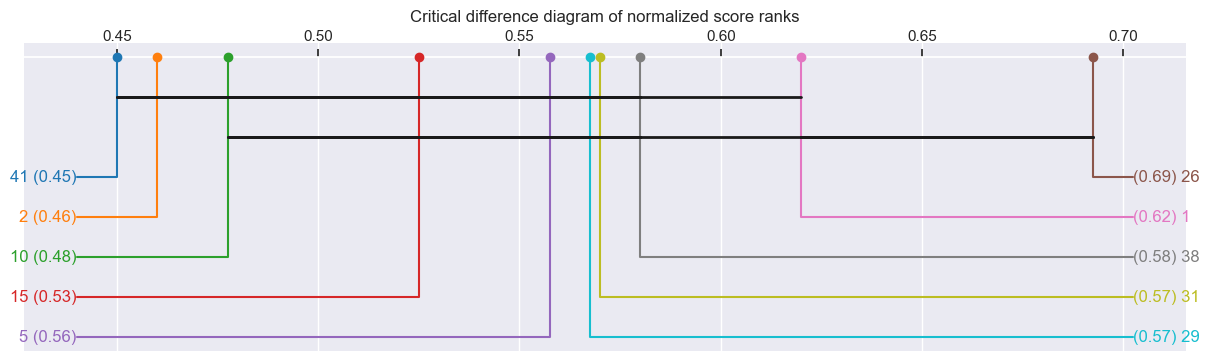

Best configuration by average rank: 41
Configurations not significantly different from the best: [41, 2, 10, 15, 5, 29, 31, 38, 1]


,lhs,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,wins
0,10,7.275,6.0,5.188683,0.042326,0.017795,2
1,2,7.950,5.0,7.218033,0.063405,0.021808,1
2,41,7.975,4.0,8.368094,0.087352,0.015579,8
3,29,8.575,8.0,5.830457,0.058405,0.023632,6
4,5,8.600,7.0,6.075592,0.053141,0.021217,1
5,15,9.050,8.0,7.815009,0.075081,0.017424,10
6,1,9.175,9.0,4.545426,0.048723,0.026793,0
7,31,9.300,7.0,6.219077,0.062981,0.028904,2
8,38,9.675,8.0,6.673282,0.082420,0.022443,4


In [32]:
# Statistical comparison of top 10 hyperparameter configurations
topk=summary.head(10).lhs.tolist()
data=(results.loc[(results['model']==model) & (results['lhs'].isin(topk)),['lhs','project','RelMSE']].
    pivot(index='project',columns='lhs',values='RelMSE')) 
comparison = model_comparison(data)
best_lhs = comparison["best_lhs"] # best configuration by average rank
best_group = comparison["best_not_significantly_different"] # configurations not significantly different from the best one

summary[summary['lhs'].isin(best_group)].sort_values('mean_rank')

In [33]:
lhs_choice = 41
models[f'fastai-{lhs_choice}'] = data[lhs_choice]

### Save best models' performance

In [36]:
models.to_csv(f"{work_dir}/selected_models_results.csv", index=False)

## Model benchmarking (first approach)
Using the best parameterization of each model

Friedman's test p-value: 2.7794616066403497e-28
Reject null hypothesis that all configurations are equally good
Conover's test for all pairs of configurations...



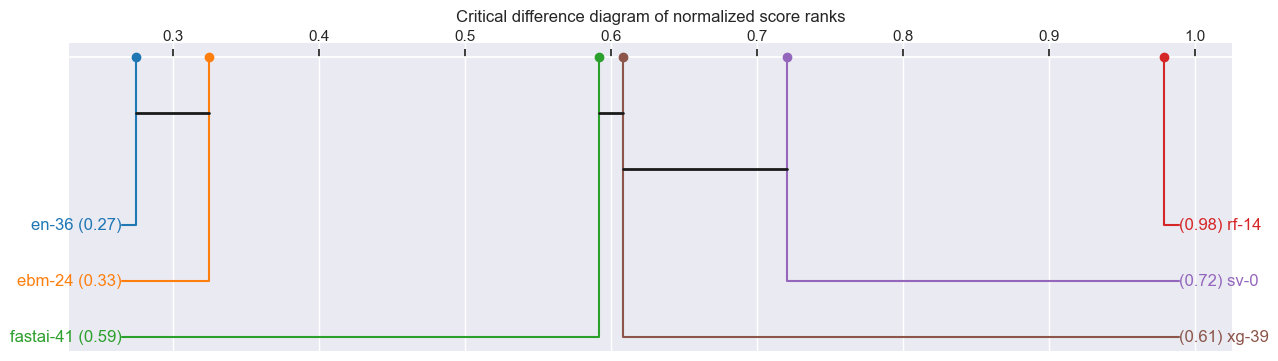

Best configuration by average rank: en-36
Configurations not significantly different from the best: ['en-36', 'ebm-24']


,lhs,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,wins
0,en-36,1.65,1.0,1.026570,0.016238,0.001411,25
1,ebm-24,1.95,2.0,0.638508,0.014880,0.001782,8


In [41]:
# Rank the models (lower RelMSE gets better rank) 
ranks = models.rank(axis=1, ascending=True, method="average")

# Summarize the performance of each model
summary = pd.DataFrame({
    "mean_rank": ranks.mean(),
    "median_rank": ranks.median(),
    "std_rank": ranks.std(),
    "mean_RelMSE": models.mean(),
    "median_RelMSE": models.median(),
    "wins": models.idxmin(axis=1).value_counts(),
})
summary["wins"] = summary["wins"].fillna(0).astype(int)

summary = (
    summary
    .sort_values(["mean_rank", "mean_RelMSE"])
    .reset_index()
    .rename(columns={"index": "lhs"})
)

# Statistical comparison of the selected models
comparison = model_comparison(models)
best_model = comparison["best_lhs"] # best configuration by average rank
best_group = comparison["best_not_significantly_different"] # configurations not significantly different from the best one

summary[summary['lhs'].isin(best_group)].sort_values('mean_rank')

In [42]:
summary

,lhs,mean_rank,median_rank,std_rank,mean_RelMSE,median_RelMSE,wins
0,en-36,1.650,1.0,1.026570,0.016238,0.001411,25
1,ebm-24,1.950,2.0,0.638508,0.014880,0.001782,8
2,fastai-41,3.550,3.5,1.616422,0.087352,0.015579,7
3,xg-39,3.650,4.0,0.769615,0.028742,0.016187,0
4,sv-0,4.325,4.5,0.828576,0.034062,0.024987,0
5,rf-14,5.875,6.0,0.334932,0.176734,0.177815,0
